In [1]:
import numpy as np
import pandas as pd
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Environment ready!")

NumPy: 2.5.4
Pandas: 2.2.3
Scikit-learn: 1.9.1
Environment ready!


In [5]:
%pip install scikit-learn joblib matplotlib 

  Using cached scikit_learn-1.9.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 114.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 155.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 127.7 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [3]:
from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer()

# Convert to Pandas DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add target column
df["target"] = data.target

# Display first 5 rows
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
print("Dataset shape:", df.shape)
print("Number of features:", len(data.feature_names))
print("Target classes:", data.target_names)

print("\nClass distribution:")
print(df["target"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

Dataset shape: (569, 31)
Number of features: 30
Target classes: ['malignant' 'benign']

Class distribution:
target
1    357
0    212
Name: count, dtype: int64

Missing values: 0


In [5]:
from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create a pipeline with scaling and Logistic Regression
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Train the model
lr_model.fit(X_train, y_train)

# Predict on test data
lr_pred = lr_model.predict(X_test)

# Predict probabilities for AUC
lr_prob = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [7]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_auc = roc_auc_score(y_test, lr_prob)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
lr_mcc = matthews_corrcoef(y_test, lr_pred)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("AUC      :", round(lr_auc, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("MCC      :", round(lr_mcc, 4))

Logistic Regression Results
---------------------------
Accuracy : 0.9825
AUC      : 0.9954
Precision: 0.9861
Recall   : 0.9861
F1 Score : 0.9861
MCC      : 0.9623


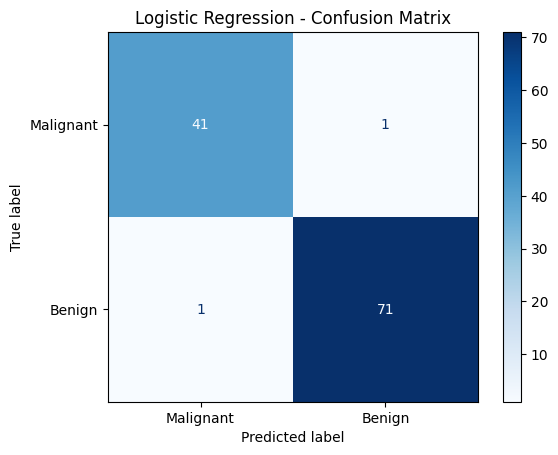

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [9]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree training completed!")

Decision Tree training completed!


In [10]:
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_auc = roc_auc_score(y_test, dt_prob)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)
dt_mcc = matthews_corrcoef(y_test, dt_pred)

print("Decision Tree Results")
print("---------------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("AUC      :", round(dt_auc, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("MCC      :", round(dt_mcc, 4))

Decision Tree Results
---------------------------
Accuracy : 0.9211
AUC      : 0.9163
Precision: 0.9565
Recall   : 0.9167
F1 Score : 0.9362
MCC      : 0.8341


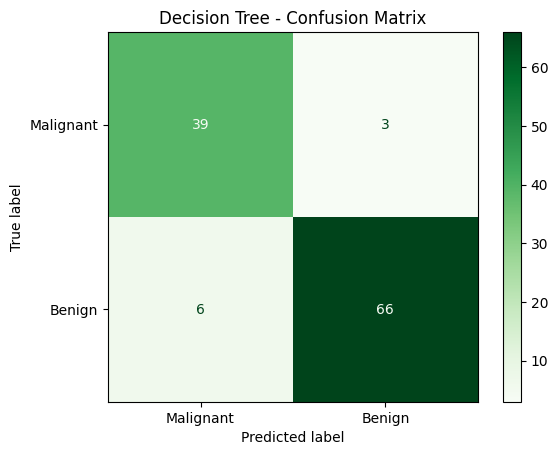

In [11]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Greens"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [12]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)
knn_prob = knn_model.predict_proba(X_test)[:, 1]

print("KNN training completed!")

KNN training completed!


In [13]:
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_auc = roc_auc_score(y_test, knn_prob)
knn_precision = precision_score(y_test, knn_pred)
knn_recall = recall_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred)
knn_mcc = matthews_corrcoef(y_test, knn_pred)

print("KNN Results")
print("---------------------------")
print("Accuracy :", round(knn_accuracy, 4))
print("AUC      :", round(knn_auc, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))
print("MCC      :", round(knn_mcc, 4))

KNN Results
---------------------------
Accuracy : 0.9561
AUC      : 0.9788
Precision: 0.9589
Recall   : 0.9722
F1 Score : 0.9655
MCC      : 0.9054


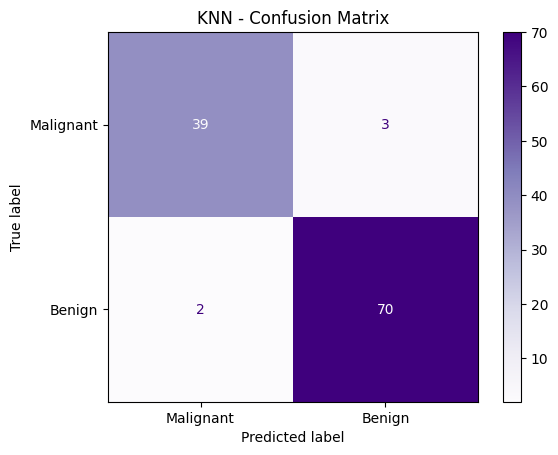

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Purples"
)

plt.title("KNN - Confusion Matrix")
plt.show()

In [15]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)
nb_prob = nb_model.predict_proba(X_test)[:, 1]

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [16]:
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_auc = roc_auc_score(y_test, nb_prob)
nb_precision = precision_score(y_test, nb_pred)
nb_recall = recall_score(y_test, nb_pred)
nb_f1 = f1_score(y_test, nb_pred)
nb_mcc = matthews_corrcoef(y_test, nb_pred)

print("Naive Bayes Results")
print("---------------------------")
print("Accuracy :", round(nb_accuracy, 4))
print("AUC      :", round(nb_auc, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("MCC      :", round(nb_mcc, 4))

Naive Bayes Results
---------------------------
Accuracy : 0.9386
AUC      : 0.9878
Precision: 0.9452
Recall   : 0.9583
F1 Score : 0.9517
MCC      : 0.8676


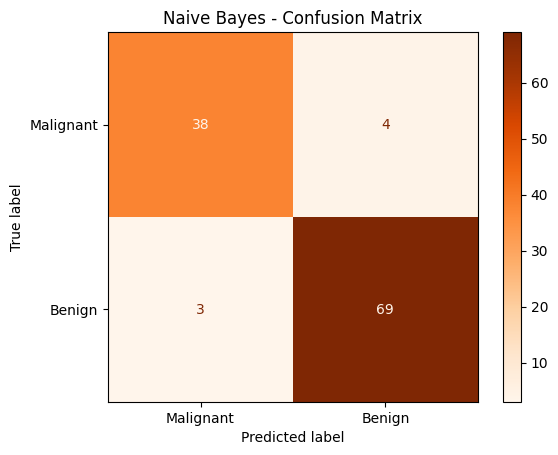

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Oranges"
)

plt.title("Naive Bayes - Confusion Matrix")
plt.show()

In [18]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    )
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)[:, 1]

print("SVM training completed!")

SVM training completed!


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [19]:
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_auc = roc_auc_score(y_test, svm_prob)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)
svm_mcc = matthews_corrcoef(y_test, svm_pred)

print("SVM Results")
print("---------------------------")
print("Accuracy :", round(svm_accuracy, 4))
print("AUC      :", round(svm_auc, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))
print("MCC      :", round(svm_mcc, 4))

SVM Results
---------------------------
Accuracy : 0.9825
AUC      : 0.995
Precision: 0.9861
Recall   : 0.9861
F1 Score : 0.9861
MCC      : 0.9623


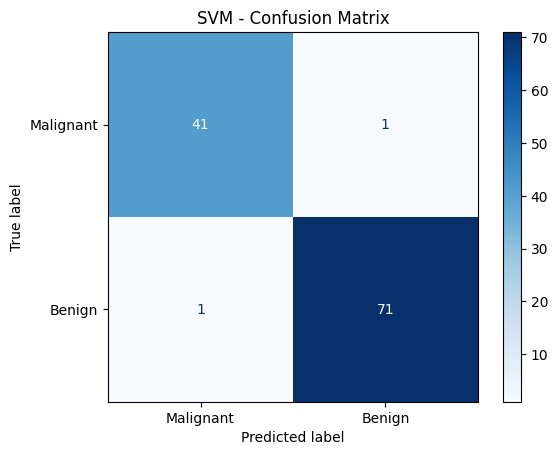

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Blues"
)

plt.title("SVM - Confusion Matrix")
plt.show()

In [21]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Naive Bayes",
        "SVM"
    ],
    "Accuracy": [lr_accuracy, dt_accuracy, knn_accuracy, nb_accuracy, svm_accuracy],
    "AUC": [lr_auc, dt_auc, knn_auc, nb_auc, svm_auc],
    "Precision": [lr_precision, dt_precision, knn_precision, nb_precision, svm_precision],
    "Recall": [lr_recall, dt_recall, knn_recall, nb_recall, svm_recall],
    "F1": [lr_f1, dt_f1, knn_f1, nb_f1, svm_f1],
    "MCC": [lr_mcc, dt_mcc, knn_mcc, nb_mcc, svm_mcc]
})

display(results.round(4))

results.to_csv("model_comparison.csv", index=False)
print("Comparison table saved!")

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9211,0.9163,0.9565,0.9167,0.9362,0.8341
2,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
4,SVM,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


Comparison table saved!


In [22]:
import os
import joblib

os.makedirs("model", exist_ok=True)

models = {
    "logistic_regression": lr_model,
    "decision_tree": dt_model,
    "knn": knn_model,
    "naive_bayes": nb_model,
    "svm": svm_model
}

for name, model in models.items():
    joblib.dump(model, f"model/{name}.joblib")

print("All 5 models saved successfully!")

All 5 models saved successfully!


In [23]:
test_data = X_test.copy()
test_data["target"] = y_test

test_data.to_csv("test_data.csv", index=False)

print("Test data saved!")
print("Shape:", test_data.shape)

Test data saved!
Shape: (114, 31)


In [24]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this directory:")
print(os.listdir())

Current working directory:
/home/s2025ns04107/ML Assignment

Files in this directory:
['app_creation.ipynb', 'ML_Assignment.ipynb', 'test_data.csv', '.ipynb_checkpoints', 'model_comparison.csv', 'model']
